# SmartTherm hybrid model experiment

This notebook is a **separate, research-only comparison** of CPU ten-minute temperature forecasts. It compares direct telemetry models, a physics ODE, and the proposed stack:

**CPU telemetry → physics ODE + Gradient Boosting → final XGBoost**, with the final XGBoost also receiving telemetry features.

- Gradient Boosting and direct XGBoost use the project telemetry features. **CPU power is excluded** from both so readings without power remain usable.
- The ODE uses valid CPU temperature/power samples with positive power from historical sessions; the newest power-bearing session is excluded as the current run.
- The stack trains on out-of-fold predictions, then evaluates on chronological validation and test partitions. This avoids training the combiner on in-sample base-model predictions.
- Invalid rows, missing CPU temperatures, missing ten-minute targets, and discontinuous windows are excluded. Adjacent thermal CSV files are joined only across gaps of at most 20 seconds; the ten-minute target tolerance is unchanged.
- Results here are experimental and do not replace the production model registry.


In [1]:
from pathlib import Path
import sys, csv, math, json
from datetime import timedelta
from dataclasses import replace
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "ThermalCollector").is_dir():
    ROOT = ROOT.parent
ML_DIR = ROOT / "ml-integration"
sys.path.insert(0, str(ML_DIR))

from smarttherm_ml.dataset import build_examples, discover_csv_files, load_points, _parse_timestamp
from smarttherm_ml.features import FEATURE_NAMES

HORIZON_SECONDS = 600
MAX_GAP_SECONDS = 20
ODE_INTERVAL_SECONDS = 20
ODE_INTERVAL_TOLERANCE_SECONDS = 5
ODE_MIN_TRANSITIONS = 120

files = discover_csv_files(ROOT)
points, rejected_rows = load_points(files)
print(f"Project root: {ROOT}")
print(f"Telemetry CSV files discovered: {len(files)}")
print(f"Valid sensor rows after project validation: {len(points):,}")
print(f"Invalid sensor rows rejected by project loader: {dict(rejected_rows)}")


Project root: C:\Users\rithv\OneDrive\Documents\github\smarttherm
Telemetry CSV files discovered: 45
Valid sensor rows after project validation: 7,207
Invalid sensor rows rejected by project loader: {}


## Power coverage for the physics branch

The base Gradient Boosting and direct XGBoost models can use every valid CPU example, including sessions with no power sensor. The ODE requires paired CPU temperature and power. Historical short power sessions can contribute valid 20-second transitions even when they lack a ten-minute forecast target. The newest power-bearing session is excluded as the current run, even if it has already accumulated some ten-minute labels. The versioned training CSVs are preferred for ODE fitting; duplicate system CSV samples are skipped when they match a versioned sample within two seconds with the same temperature and power.

For CPU forecast examples, adjacent thermal CSVs are joined into one continuous recording only when neighboring timestamps are no more than 20 seconds apart. The target builder still splits at gaps over 20 seconds and still requires a CPU-temperature target around ten minutes later. This recovers forecasts that cross file boundaries without relaxing the forecast horizon. Process telemetry files remain excluded because they do not contain CPU-temperature targets.


In [2]:
def first_nonempty(row, *names):
    for name in names:
        value = row.get(name)
        if value is not None and str(value).strip():
            return str(value).strip()
    return None

def parse_number(value, low=None, high=None):
    try:
        number = float(value)
    except (TypeError, ValueError):
        return None
    if not math.isfinite(number):
        return None
    if low is not None and number < low:
        return None
    if high is not None and number > high:
        return None
    return number

def read_raw_records(csv_files):
    all_records = []
    training_records = []
    source_rows = []
    for path in csv_files:
        count = 0
        with path.open("r", newline="", encoding="utf-8-sig") as handle:
            reader = csv.DictReader(handle)
            for row in reader:
                count += 1
                timestamp = _parse_timestamp(first_nonempty(row, "timestamp", "Timestamp"))
                if timestamp is None:
                    continue
                session_id = first_nonempty(row, "sessionId", "session_id") or path.name
                temperature = parse_number(first_nonempty(row, "cpuTemperatureC", "CPU_Temp"), 0, 150)
                power = parse_number(first_nonempty(row, "cpuPowerW", "CPU_Power_W"), 0, 1000)
                record = {"session_id": session_id, "timestamp": timestamp,
                          "temperature": temperature, "power": power, "path": path,
                          "is_versioned": path.name.startswith("training_telemetry_")}
                all_records.append(record)
                if record["is_versioned"]:
                    training_records.append(record)
        source_rows.append({"file": str(path.relative_to(ROOT)), "rows": count,
                            "versioned_training_csv": path.name.startswith("training_telemetry_")})
    return all_records, training_records, source_rows

all_raw_records, versioned_records, source_rows = read_raw_records(files)
training_signals = [r for r in versioned_records if r["temperature"] is not None]
training_positive = [r for r in training_signals if r["power"] is not None and r["power"] > 0]

def duplicates_training_sample(record):
    if record["is_versioned"] or record["temperature"] is None or record["power"] is None:
        return False
    stamp = record["timestamp"].timestamp()
    return any(r["temperature"] == record["temperature"] and r["power"] == record["power"]
               and abs(r["timestamp"].timestamp() - stamp) <= 2 for r in training_positive)

# Keep versioned data and legacy power records that are not duplicate writes of the same sample.
ode_records = [r for r in all_raw_records if r["is_versioned"] or not duplicates_training_sample(r)]
ode_records = [r for r in ode_records if r["temperature"] is not None]

# Match power to project examples; sessions without a power sensor remain in the base-model data.
power_lookup = {}
power_lookup_by_timestamp = {}
for record in all_raw_records:
    power_lookup[(record["session_id"], record["timestamp"])] = record
    # Forecast examples may now span adjoining thermal CSV files. Power is paired by exact
    # timestamp; prefer versioned data when duplicate timestamps are present.
    key = record["timestamp"]
    if key not in power_lookup_by_timestamp or record["is_versioned"]:
        power_lookup_by_timestamp[key] = record
versioned_session_ids = {r["session_id"] for r in versioned_records}

def same_sensor_sample(a, b):
    if abs((a.timestamp - b.timestamp).total_seconds()) > 2:
        return False
    av = (a.cpu_temperature_c, a.cpu_utilization_percent)
    bv = (b.cpu_temperature_c, b.cpu_utilization_percent)
    if av[0] is None or bv[0] is None or abs(av[0] - bv[0]) > 0.1:
        return False
    if av[1] is None or bv[1] is None or abs(av[1] - bv[1]) > 1.0:
        return False
    return True

# Root telemetry CSVs mirror the versioned training CSVs. Deduplicate these near-identical writes
# before splitting so copies of the same observation cannot inflate held-out scores.
clean_points = []
window_start = 0
for point in sorted(points, key=lambda p: (p.timestamp, p.session_id not in versioned_session_ids)):
    while window_start < len(clean_points) and (point.timestamp - clean_points[window_start].timestamp).total_seconds() > 2:
        window_start += 1
    duplicate_index = next((i for i in range(len(clean_points) - 1, window_start - 1, -1)
                            if same_sensor_sample(point, clean_points[i])), None)
    if duplicate_index is None:
        clean_points.append(point)
    elif point.session_id in versioned_session_ids and clean_points[duplicate_index].session_id not in versioned_session_ids:
        clean_points[duplicate_index] = point

# Session IDs are sometimes generated from filenames, even when capture was simply rotated
# into another CSV. Join adjacent observations across files only when timestamps remain within
# the existing 20-second continuity limit. build_examples still breaks any longer time gap.
continuous_points = []
continuous_session = 0
previous_timestamp = None
for point in sorted(clean_points, key=lambda p: p.timestamp):
    if previous_timestamp is None or (point.timestamp - previous_timestamp).total_seconds() > MAX_GAP_SECONDS:
        continuous_session += 1
    continuous_points.append(replace(point, session_id=f"continuous_{continuous_session}"))
    previous_timestamp = point.timestamp

examples_by_component, rejected_targets = build_examples(continuous_points)
cpu_examples = sorted(examples_by_component["CPU"], key=lambda e: e.timestamp)

# Use the newest power-bearing sessions as validation and test. This gives the ODE earlier
# power-bearing sessions to calibrate on, while retaining all older CPU-temperature-only data
# for the telemetry models.
power_sessions = defaultdict(list)
for record in ode_records:
    if record["temperature"] is not None and record["power"] is not None and record["power"] > 0:
        power_sessions[record["session_id"]].append(record)
all_ordered_power_sessions = sorted(
    [(min(r["timestamp"] for r in rows), sid, rows) for sid, rows in power_sessions.items()],
    key=lambda item: item[0])
if not all_ordered_power_sessions:
    raise RuntimeError("No paired positive-power sessions were found.")
# Treat the newest power-bearing session as the current run and exclude it even if it has
# grown long enough to produce a few ten-minute labels during this analysis.
current_power_session_id = all_ordered_power_sessions[-1][1]
current_session_start = all_ordered_power_sessions[-1][0]
cpu_examples = [e for e in cpu_examples if e.timestamp < current_session_start]

def has_cpu_label(item):
    return any(item[0] <= example.timestamp <= max(r["timestamp"] for r in item[2])
               for example in cpu_examples)
ordered_power_sessions = [item for item in all_ordered_power_sessions[:-1] if has_cpu_label(item)]
# Keep historical short runs for ODE calibration; only exclude the current newest run.
model_ode_records = [r for r in ode_records if r["session_id"] != current_power_session_id]
if len(ordered_power_sessions) < 3:
    raise RuntimeError("Need at least three labeled positive-power sessions for a power-aware train/validation/test comparison.")
validation_start = ordered_power_sessions[-2][0]
test_start = ordered_power_sessions[-1][0]
train_examples = [e for e in cpu_examples if e.timestamp + timedelta(seconds=HORIZON_SECONDS) < validation_start]
validation_examples = [e for e in cpu_examples if validation_start <= e.timestamp < test_start]
test_examples = [e for e in cpu_examples if e.timestamp >= test_start]
if not train_examples or not validation_examples or not test_examples:
    raise RuntimeError("The power-aware chronological split did not produce all three partitions.")

print(f"Invalid target candidates rejected: {dict(rejected_targets)}")
print(f"Duplicate cross-file sensor observations removed: {len(points) - len(clean_points):,}")
print(f"Distinct positive-power sessions: {len(ordered_power_sessions)}")
display(pd.DataFrame([
    {"partition": name, "ten_minute_examples": len(rows),
     "first_timestamp": min(e.timestamp for e in rows),
     "last_timestamp": max(e.timestamp for e in rows)}
    for name, rows in [("train", train_examples), ("validation", validation_examples), ("test", test_examples)]
]))
coverage = pd.DataFrame([
    {"measure": "All valid CPU ten-minute examples after deduplication and continuity merge", "count": len(cpu_examples)},
    {"measure": "Versioned CPU temperature rows", "count": sum(r["temperature"] is not None for r in versioned_records)},
    {"measure": "Versioned rows with positive paired CPU power", "count": len(training_positive)},
    {"measure": "Distinct ODE signal records after duplicate filtering", "count": len(ode_records)},
    {"measure": "Labeled positive-power sessions for chronological split", "count": len(ordered_power_sessions)},
    {"measure": "Newest/current power session excluded from fitting", "count": 1},
    {"measure": "Base training examples with positive current power", "count": sum(
        (rec := power_lookup_by_timestamp.get(e.timestamp)) is not None
        and rec["power"] is not None and rec["power"] > 0 for e in cpu_examples)},
])
display(coverage)
display(pd.DataFrame(source_rows).sort_values("file").reset_index(drop=True))
print(f"Telemetry features ({len(FEATURE_NAMES)}; no CPU power): {', '.join(FEATURE_NAMES)}")


Invalid target candidates rejected: {'insufficient_feature_history': 52, 'cpu_missing_current_temperature': 1379, 'missing_ten_minute_target': 2995, 'gpu_missing_current_temperature': 976}
Duplicate cross-file sensor observations removed: 1,332
Distinct positive-power sessions: 3


,partition,ten_minute_examples,first_timestamp,last_timestamp
0,train,919,2026-10-23 16:24:36+00:00,2026-10-26 15:18:33.618123+00:00
1,validation,80,2026-10-26 16:03:42.151603+00:00,2026-10-26 16:14:21.782809+00:00
2,test,125,2026-10-26 16:29:37.328876+00:00,2026-10-26 16:44:20.403023+00:00


,measure,count
0,All valid CPU ten-minute examples after dedupl...,1124
1,Versioned CPU temperature rows,1332
2,Versioned rows with positive paired CPU power,1083
3,Distinct ODE signal records after duplicate fi...,3619
4,Labeled positive-power sessions for chronologi...,3
5,Newest/current power session excluded from fit...,1
6,Base training examples with positive current p...,248


,file,rows,versioned_training_csv
0,ThermalCollector\data\training_telemetry_24dd6...,249,True
1,ThermalCollector\data\training_telemetry_264bf...,156,True
2,ThermalCollector\data\training_telemetry_82127...,18,True
3,ThermalCollector\data\training_telemetry_ba822...,210,True
4,ThermalCollector\data\training_telemetry_c6b08...,159,True
5,ThermalCollector\data\training_telemetry_dd007...,69,True
6,ThermalCollector\data\training_telemetry_dd138...,472,True
7,ThermalCollector\telemetry.csv,803,False
8,ThermalCollector\telemetry_20261012_004446_285...,6,False
9,ThermalCollector\telemetry_20261012_005457_525...,4,False


Telemetry features (15; no CPU power): temperature_current_c, temperature_mean_30s_c, temperature_mean_60s_c, temperature_mean_300s_c, temperature_min_60s_c, temperature_max_60s_c, temperature_slope_30s_c_per_min, temperature_slope_300s_c_per_min, cpu_utilization_percent, cpu_utilization_mean_60s_percent, cpu_clock_mhz, cpu_clock_mean_60s_mhz, gpu_utilization_percent, gpu_utilization_mean_60s_percent, memory_utilization_percent


## Direct telemetry models

Both direct models use the same project feature contract and chronological train/validation/test split. CPU power is deliberately absent from their feature matrix so the models can use older sessions with no power readings.


In [ ]:
def feature_matrix(rows):
    return np.asarray([[np.nan if e.features.get(name) is None else float(e.features[name])
                        for name in FEATURE_NAMES] for e in rows], dtype=float)

def target_vector(rows):
    return np.asarray([e.target_c for e in rows], dtype=float)

def persistence_vector(rows):
    return np.asarray([e.persistence_prediction_c for e in rows], dtype=float)

def model_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = predicted - actual
    return {"MAE (°C)": float(np.mean(np.abs(error))),
            "RMSE (°C)": float(np.sqrt(np.mean(error ** 2))),
            "Mean signed error (°C)": float(np.mean(error)),
            "R²": float(1.0 - np.sum(error ** 2) / np.sum((actual - np.mean(actual)) ** 2))}

def make_gradient_boosting():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", GradientBoostingRegressor(
            loss="huber", n_estimators=150, learning_rate=0.04,
            max_depth=3, min_samples_leaf=5, random_state=42))])

def make_direct_xgboost():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", XGBRegressor(
            objective="reg:squarederror", n_estimators=250, max_depth=4,
            learning_rate=0.04, min_child_weight=5, subsample=0.85,
            colsample_bytree=0.9, reg_lambda=2.0, tree_method="hist",
            n_jobs=2, random_state=42))])

y_train = target_vector(train_examples)
y_validation = target_vector(validation_examples)
y_test = target_vector(test_examples)

telemetry_gb = make_gradient_boosting().fit(feature_matrix(train_examples), y_train)
telemetry_xgb = make_direct_xgboost().fit(feature_matrix(train_examples), y_train)

base_predictions = {
    "Persistence": {"validation": persistence_vector(validation_examples), "test": persistence_vector(test_examples)},
    "Gradient Boosting": {"validation": telemetry_gb.predict(feature_matrix(validation_examples)), "test": telemetry_gb.predict(feature_matrix(test_examples))},
    "Direct XGBoost": {"validation": telemetry_xgb.predict(feature_matrix(validation_examples)), "test": telemetry_xgb.predict(feature_matrix(test_examples))},
}
base_rows = []
for model_name, split_predictions in base_predictions.items():
    for partition, actual in [("validation", y_validation), ("test", y_test)]:
        base_rows.append({"model": model_name, "partition": partition,
                          **model_metrics(actual, split_predictions[partition])})
base_score_table = pd.DataFrame(base_rows)
display(base_score_table.pivot(index="model", columns="partition", values=["MAE (°C)", "RMSE (°C)", "Mean signed error (°C)", "R²"]).round(3))


## Physics ODE calibration

We fit `dT/dt = a·P − b·T + c` using temperature/power windows averaged over about 20 seconds. This reduces the effect of integer-degree temperature quantization in five-second samples. We keep the project’s physical stability limits (`0 < a < 0.1`, `0 < b < 0.02`) and report a rejected fit rather than forcing coefficients into range. Ten-minute predictions hold the latest observed power constant; that assumption is explicitly evaluated below.


In [4]:
def fit_physics_ode(records, cutoff=None, interval_seconds=ODE_INTERVAL_SECONDS,
                    tolerance_seconds=ODE_INTERVAL_TOLERANCE_SECONDS):
    grouped = defaultdict(list)
    for record in records:
        if record["temperature"] is None:
            continue
        if cutoff is not None and record["timestamp"] >= cutoff:
            continue
        grouped[record["session_id"]].append(record)
    design, response = [], []
    for session_records in grouped.values():
        session_records.sort(key=lambda r: r["timestamp"])
        # Split into continuous segments; missing/zero power breaks ODE calibration windows.
        segment = []
        segments = []
        for r in session_records:
            if segment and (r["timestamp"] - segment[-1]["timestamp"]).total_seconds() > MAX_GAP_SECONDS:
                segments.append(segment); segment = []
            segment.append(r)
        if segment:
            segments.append(segment)
        for segment in segments:
            stamps = [r["timestamp"].timestamp() for r in segment]
            for i, start in enumerate(segment):
                choices = [j for j in range(i + 1, len(segment))
                           if interval_seconds - tolerance_seconds <= stamps[j] - stamps[i]
                           <= interval_seconds + tolerance_seconds]
                if not choices:
                    continue
                j = min(choices, key=lambda k: abs((stamps[k] - stamps[i]) - interval_seconds))
                window = segment[i:j + 1]
                if any((window[k + 1]["timestamp"] - window[k]["timestamp"]).total_seconds() > MAX_GAP_SECONDS
                       for k in range(len(window) - 1)):
                    continue
                if any(r["power"] is None or r["power"] <= 0 for r in window):
                    continue
                elapsed = stamps[j] - stamps[i]
                avg_power = float(np.mean([r["power"] for r in window[:-1]]))
                avg_temp = float(np.mean([r["temperature"] for r in window]))
                design.append([avg_power, avg_temp, 1.0])
                response.append((window[-1]["temperature"] - window[0]["temperature"]) / elapsed)
    if len(design) < ODE_MIN_TRANSITIONS:
        return {"accepted": False, "reason": f"Only {len(design)} usable windows; need {ODE_MIN_TRANSITIONS}.",
                "transitions": len(design)}
    coef, *_ = np.linalg.lstsq(np.asarray(design), np.asarray(response), rcond=None)
    a, temperature_gain, c = map(float, coef)
    b = -temperature_gain
    residual = np.asarray(response) - np.asarray(design) @ coef
    accepted = 0 < a < 0.1 and 1e-6 < b < 0.02
    return {"accepted": accepted, "reason": "stable fit" if accepted else "outside physical stability limits",
            "power_gain_c_per_joule": a, "cooling_rate_per_second": b,
            "offset_c_per_second": c, "transitions": len(design),
            "derivative_rmse_c_per_second": float(np.sqrt(np.mean(residual ** 2)))}

def ode_predict(fit, temperature_c, power_w, seconds=HORIZON_SECONDS):
    if not fit or not fit.get("accepted") or temperature_c is None or power_w is None or power_w <= 0:
        return np.nan
    a, b, c = fit["power_gain_c_per_joule"], fit["cooling_rate_per_second"], fit["offset_c_per_second"]
    equilibrium = (a * power_w + c) / b
    return float(equilibrium + (temperature_c - equilibrium) * np.exp(-b * seconds))

first_validation_time = min(e.timestamp for e in validation_examples)
train_ode_records = [r for r in model_ode_records if r["timestamp"] < first_validation_time]
ode_fit = fit_physics_ode(train_ode_records)
display(pd.DataFrame([ode_fit]))
print(f"ODE calibration only used positive-power records before validation ({len(train_ode_records)} records).")


,accepted,reason,power_gain_c_per_joule,cooling_rate_per_second,offset_c_per_second,transitions,derivative_rmse_c_per_second
0,True,stable fit,0.000512,0.000636,0.034772,234,0.601515


ODE calibration only used positive-power records before validation (2784 records).


## Train the stacker on out-of-fold base predictions

The power-aware validation session is used to train the meta-model on forecasts from Gradient Boosting and the ODE, both fitted only on earlier sessions. These are out-of-fold base predictions. The final XGBoost receives those two forecasts plus the raw telemetry features. The newest power-bearing session remains untouched for the final stack test.


We also screen lower-capacity meta-models and a 60-second mean-power input to reduce overfitting and power-sensor noise. These variants are compared on the same held-out session as an exploratory check; a future session should confirm any apparent improvement.


A separate direct telemetry XGBoost forecast is also tested as a third base signal. The final XGBoost remains a distinct combiner and receives telemetry features plus the ODE, Gradient Boosting, and direct XGBoost forecasts.


In [ ]:
def raw_feature_vector(example):
    return np.asarray([np.nan if example.features.get(name) is None else float(example.features[name])
                       for name in FEATURE_NAMES], dtype=float)

def prediction_power(example, window_seconds=None):
    if window_seconds is None:
        record = power_lookup_by_timestamp.get(example.timestamp)
        return None if record is None else record["power"]
    start = example.timestamp - timedelta(seconds=window_seconds)
    recent = [r["power"] for r in ode_records
              if start <= r["timestamp"] <= example.timestamp
              and r["power"] is not None and r["power"] > 0]
    return float(np.mean(recent)) if recent else None

def stack_vector(example, gb_prediction, ode_fit_value, power_window_seconds=None):
    temperature = example.features.get("temperature_current_c")
    power = prediction_power(example, power_window_seconds)
    ode_value = ode_predict(ode_fit_value, temperature, power)
    availability = float(np.isfinite(ode_value))
    return np.concatenate([raw_feature_vector(example), [gb_prediction, ode_value, availability]])

def make_oof_stack_training(rows, power_records, fractions=(0.35, 0.50, 0.65, 0.80, 0.95)):
    ordered = sorted(rows, key=lambda e: e.timestamp)
    unique_times = sorted({e.timestamp for e in ordered})
    boundaries = sorted(set([0] + [min(len(unique_times)-1, int(f * len(unique_times))) for f in fractions] + [len(unique_times)]))
    oof_x, oof_y, meta = [], [], []
    for start_idx, end_idx in zip(boundaries[:-1], boundaries[1:]):
        if start_idx == 0 or end_idx <= start_idx:
            continue
        start_time = unique_times[start_idx]
        end_time = unique_times[end_idx] if end_idx < len(unique_times) else unique_times[-1] + timedelta(microseconds=1)
        fold_train = [e for e in ordered if e.timestamp + timedelta(seconds=HORIZON_SECONDS) < start_time]
        fold_valid = [e for e in ordered if start_time <= e.timestamp < end_time]
        if len(fold_train) < 60 or len(fold_valid) < 10:
            continue
        fold_features = feature_matrix(fold_train)
        fold_y = target_vector(fold_train)
        gb = make_gradient_boosting().fit(fold_features, fold_y)
        direct_xgb = make_direct_xgboost().fit(fold_features, fold_y)
        fold_ode = fit_physics_ode([r for r in power_records if r["timestamp"] < start_time])
        valid_features = feature_matrix(fold_valid)
        fold_gb_predictions = gb.predict(valid_features)
        fold_xgb_predictions = direct_xgb.predict(valid_features)
        for example, gb_prediction, xgb_prediction in zip(fold_valid, fold_gb_predictions, fold_xgb_predictions):
            vector = np.concatenate([stack_vector(example, gb_prediction, fold_ode), [xgb_prediction]])
            oof_x.append(vector)
            oof_y.append(example.target_c)
            meta.append({"timestamp": example.timestamp, "session_id": example.session_id,
                         "ode_available": bool(np.isfinite(vector[-3])),
                         "fold_train_examples": len(fold_train)})
    return np.asarray(oof_x, dtype=float), np.asarray(oof_y, dtype=float), pd.DataFrame(meta)

# Validation forecasts are out-of-fold: all three base predictors were fitted on earlier train data.
stack_gb = make_gradient_boosting().fit(feature_matrix(train_examples), y_train)
stack_ode = fit_physics_ode([r for r in model_ode_records if r["timestamp"] < validation_start])
validation_features = feature_matrix(validation_examples)
validation_gb_predictions = stack_gb.predict(validation_features)
validation_direct_xgb_predictions = telemetry_xgb.predict(validation_features)
validation_stack_x = np.vstack([stack_vector(e, p, stack_ode) for e, p in zip(validation_examples, validation_gb_predictions)])
validation_stack_x_60 = np.vstack([stack_vector(e, p, stack_ode, power_window_seconds=60) for e, p in zip(validation_examples, validation_gb_predictions)])
validation_stack_x_three = np.column_stack([validation_stack_x, validation_direct_xgb_predictions])
validation_stack_x_60_three = np.column_stack([validation_stack_x_60, validation_direct_xgb_predictions])
oof_ode_count = int(np.isfinite(validation_stack_x[:, -2]).sum())
print(f"Meta-training examples with out-of-fold base predictions: {len(validation_examples)}")
print(f"Rows with a valid ODE prediction: {oof_ode_count}")
print(f"Earlier-session ODE fit: {stack_ode}")

stack_compact_indices = [0, 7, 8, 10, 14, len(FEATURE_NAMES), len(FEATURE_NAMES)+1, len(FEATURE_NAMES)+2]
meta_xgb = meta_xgb_three = meta_xgb_60 = meta_ridge_60 = meta_compact_xgb = None
if len(validation_examples) >= 30 and oof_ode_count >= 30:
    meta_xgb = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", XGBRegressor(
            objective="reg:squarederror", n_estimators=80, max_depth=2,
            learning_rate=0.03, min_child_weight=4, subsample=0.9,
            colsample_bytree=0.9, reg_lambda=5.0, tree_method="hist",
            n_jobs=2, random_state=84))]).fit(validation_stack_x, y_validation)
    meta_xgb_three = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", XGBRegressor(
            objective="reg:squarederror", n_estimators=50, max_depth=1,
            learning_rate=0.025, min_child_weight=8, subsample=1.0,
            colsample_bytree=1.0, reg_lambda=20.0, gamma=0.1,
            tree_method="hist", n_jobs=2, random_state=85))]).fit(validation_stack_x_three, y_validation)
    meta_xgb_60 = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", XGBRegressor(
            objective="reg:squarederror", n_estimators=45, max_depth=1,
            learning_rate=0.025, min_child_weight=10, subsample=1.0,
            colsample_bytree=1.0, reg_lambda=20.0, gamma=0.1,
            tree_method="hist", n_jobs=2, random_state=84))]).fit(validation_stack_x_60, y_validation)
    meta_ridge_60 = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=25.0))]).fit(validation_stack_x_60, y_validation)
    meta_compact_xgb = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", XGBRegressor(
            objective="reg:squarederror", n_estimators=45, max_depth=1,
            learning_rate=0.025, min_child_weight=10, subsample=1.0,
            colsample_bytree=1.0, reg_lambda=20.0, gamma=0.1,
            tree_method="hist", n_jobs=2, random_state=84))]).fit(
                validation_stack_x_60[:, stack_compact_indices], y_validation)
else:
    print("The stack was not fitted: need at least 30 validation rows with a real ODE forecast.")

# The newest session stays untouched by the base and meta fits.
test_features = feature_matrix(test_examples)
test_gb_predictions = stack_gb.predict(test_features)
test_direct_xgb_predictions = telemetry_xgb.predict(test_features)
test_stack_x = np.vstack([stack_vector(e, p, stack_ode) for e, p in zip(test_examples, test_gb_predictions)])
test_stack_x_60 = np.vstack([stack_vector(e, p, stack_ode, power_window_seconds=60) for e, p in zip(test_examples, test_gb_predictions)])
test_stack_x_three = np.column_stack([test_stack_x, test_direct_xgb_predictions])
test_stack_x_60_three = np.column_stack([test_stack_x_60, test_direct_xgb_predictions])
stack_test_prediction = meta_xgb.predict(test_stack_x) if meta_xgb is not None else np.full(len(test_examples), np.nan)
stack_three_test_prediction = meta_xgb_three.predict(test_stack_x_three) if meta_xgb_three is not None else np.full(len(test_examples), np.nan)
stack_compact_xgb = meta_compact_xgb.predict(test_stack_x_60[:, stack_compact_indices]) if meta_compact_xgb is not None else np.full(len(test_examples), np.nan)
stack_ridge_prediction = meta_ridge_60.predict(test_stack_x_60) if meta_ridge_60 is not None else np.full(len(test_examples), np.nan)

all_predictions = dict(base_predictions)
all_predictions["Physics ODE"] = {
    "validation": np.asarray([ode_predict(stack_ode, e.features.get("temperature_current_c"), prediction_power(e)) for e in validation_examples]),
    "test": np.asarray([ode_predict(stack_ode, e.features.get("temperature_current_c"), prediction_power(e)) for e in test_examples]),
}
all_predictions["Physics ODE (60s mean power)"] = {
    "validation": np.asarray([ode_predict(stack_ode, e.features.get("temperature_current_c"), prediction_power(e, 60)) for e in validation_examples]),
    "test": np.asarray([ode_predict(stack_ode, e.features.get("temperature_current_c"), prediction_power(e, 60)) for e in test_examples]),
}
for name, prediction in [
    ("Stack: ODE + GB + telemetry → XGBoost", stack_test_prediction),
    ("Stack: ODE + GB + direct XGBoost + telemetry → XGBoost", stack_three_test_prediction),
    ("Optimized: compact XGBoost stack + 60s power", stack_compact_xgb),
    ("Optimized: Ridge stack + 60s power", stack_ridge_prediction),
]:
    all_predictions[name] = {"validation": np.full(len(validation_examples), np.nan), "test": prediction}

score_rows = []
for model_name, split_predictions in all_predictions.items():
    partitions = ["test"] if model_name.startswith(("Stack:", "Optimized:")) else ["validation", "test"]
    for partition in partitions:
        actual = y_validation if partition == "validation" else y_test
        predicted = split_predictions[partition]
        valid = np.isfinite(predicted)
        if valid.any():
            score_rows.append({"model": model_name, "partition": partition,
                               "evaluated_examples": int(valid.sum()),
                               **model_metrics(actual[valid], predicted[valid])})
        else:
            score_rows.append({"model": model_name, "partition": partition,
                               "evaluated_examples": 0, "MAE (°C)": np.nan, "RMSE (°C)": np.nan, "Mean signed error (°C)": np.nan, "R²": np.nan})
score_table = pd.DataFrame(score_rows)
display(score_table.pivot(index="model", columns="partition", values=["evaluated_examples", "MAE (°C)", "RMSE (°C)", "Mean signed error (°C)", "R²"]).round(3))


FIXED 10-MINUTE TEST — R², 125 held-out examples per model
Persistence: -0.7953
Gradient Boosting: -0.1276
Direct XGBoost: -0.3085
Physics ODE: -0.5679
Physics ODE (60s mean power): -0.5571
Stack: ODE + GB + telemetry → XGBoost: -3.8219
Stack: ODE + GB + direct XGBoost + telemetry → XGBoost: -3.9419
Optimized: compact XGBoost stack + 60s power: -4.5903
Optimized: Ridge stack + 60s power: -4.7968


## Visual comparison on held-out test data

The scatter plot shows forecasts against actual CPU temperatures for the newest power-bearing session, which was not used to fit the ODE or meta-XGBoost. The diagonal is perfect prediction. The ODE is shown only for rows where its fit and current power input are usable. The stack has no validation score because that session trained the meta-XGBoost; its test score is the unbiased comparison.


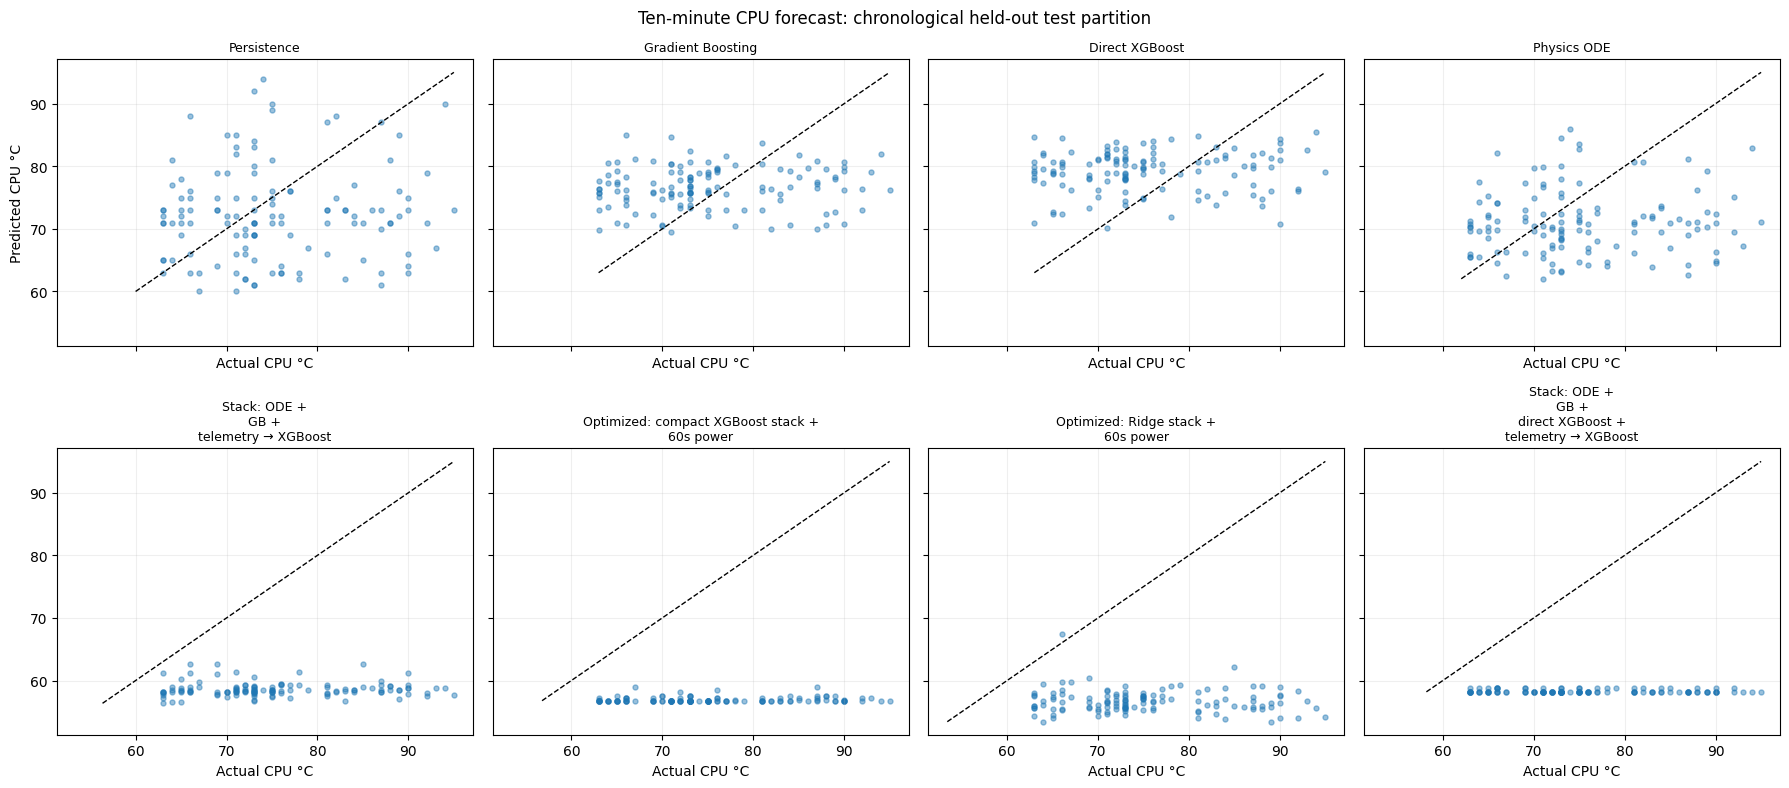

In [6]:
plot_models = ["Persistence", "Gradient Boosting", "Direct XGBoost", "Physics ODE", "Stack: ODE + GB + telemetry → XGBoost", "Optimized: compact XGBoost stack + 60s power", "Optimized: Ridge stack + 60s power", "Stack: ODE + GB + direct XGBoost + telemetry → XGBoost"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True, sharey=True)
axes = axes.ravel()
for ax, name in zip(axes, plot_models):
    prediction = all_predictions[name]["test"]
    valid = np.isfinite(prediction)
    ax.scatter(y_test[valid], prediction[valid], s=13, alpha=0.45)
    if valid.any():
        low = min(float(np.min(y_test[valid])), float(np.min(prediction[valid])))
        high = max(float(np.max(y_test[valid])), float(np.max(prediction[valid])))
        ax.plot([low, high], [low, high], linestyle="--", color="black", linewidth=1)
    ax.set_title(name.replace(" + ", " +\n"), fontsize=9)
    ax.set_xlabel("Actual CPU °C")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Predicted CPU °C")
fig.suptitle("Ten-minute CPU forecast: chronological held-out test partition")
plt.tight_layout()
plt.show()


## Refit experimental candidates on all current valid data

After the held-out comparison, the notebook refits the direct models and stack on all eligible CPU examples. This uses all currently available labels for later inspection. These full-data fits are not scored on their own training data and are **not promoted to production**. The out-of-fold results above are the honest performance comparison.


In [7]:
full_x = feature_matrix(cpu_examples)
full_y = target_vector(cpu_examples)
full_direct_xgb = make_direct_xgboost().fit(full_x, full_y)
full_gradient_boosting = make_gradient_boosting().fit(full_x, full_y)
full_ode_fit = fit_physics_ode(model_ode_records)
full_oof_x, full_oof_y, full_oof_meta = make_oof_stack_training(
    cpu_examples, model_ode_records, fractions=(0.25, 0.40, 0.55, 0.70, 0.85, 0.95))
full_stack_xgb = None
full_oof_ode_count = int(full_oof_meta["ode_available"].sum()) if not full_oof_meta.empty else 0
if len(full_oof_y) >= 30 and full_oof_ode_count >= 30:
    full_stack_xgb = Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", XGBRegressor(
            objective="reg:squarederror", n_estimators=120, max_depth=2,
            learning_rate=0.03, min_child_weight=4, subsample=0.9,
            colsample_bytree=0.9, reg_lambda=5.0, tree_method="hist",
            n_jobs=2, random_state=84))]).fit(full_oof_x, full_oof_y)

final_summary = pd.DataFrame([
    {"candidate": "Direct telemetry XGBoost", "fit_examples": len(cpu_examples), "uses_power": False, "fit_state": "fit on all valid examples"},
    {"candidate": "Direct telemetry Gradient Boosting", "fit_examples": len(cpu_examples), "uses_power": False, "fit_state": "fit on all valid examples"},
    {"candidate": "Physics ODE", "fit_examples": full_ode_fit.get("transitions", 0), "uses_power": True, "fit_state": "stable research fit" if full_ode_fit.get("accepted", False) else "rejected by stability gate"},
    {"candidate": "Stack: ODE + GB + direct XGBoost + telemetry → XGBoost", "fit_examples": len(full_oof_y), "OOF rows with ODE": full_oof_ode_count, "uses_power": "ODE only", "fit_state": f"research fit only ({full_oof_ode_count} OOF rows with ODE)" if full_stack_xgb is not None else "not fitted; insufficient OOF ODE rows"},
])
display(final_summary)
display(pd.DataFrame([full_ode_fit]))
print("Full-data candidate models are in notebook memory only; production artifacts are untouched.")


,candidate,fit_examples,uses_power,fit_state,OOF rows with ODE
0,Direct telemetry XGBoost,1124,False,fit on all valid examples,NaN
1,Direct telemetry Gradient Boosting,1124,False,fit on all valid examples,NaN
2,Physics ODE,594,True,stable research fit,NaN
3,Stack: ODE + GB + direct XGBoost + telemetry →...,843,ODE only,research fit only (57 OOF rows with ODE),57.0


,accepted,reason,power_gain_c_per_joule,cooling_rate_per_second,offset_c_per_second,transitions,derivative_rmse_c_per_second
0,True,stable fit,0.006016,0.001754,0.030281,594,0.529464


Full-data candidate models are in notebook memory only; production artifacts are untouched.


## Reading the results

- Use the chronological **test** scores to compare candidates; validation scores are for development decisions. The stack's meta-model used out-of-fold predictions from the validation session, so only its test score is reported.
- MAE and RMSE are temperature errors in °C; lower is better. Compare each candidate with Persistence.
- Mean signed error is **prediction − actual**: positive means the model overpredicts on average, and negative means it underpredicts on average. A mean near zero can still hide individual over- and underpredictions.
- If the stack does not beat Persistence and the best direct model on held-out data, keep it experimental.
- The ODE assumes constant power for ten minutes. The notebook reports its standalone score and whether the stack can exploit its prediction; poor ODE-only results do not automatically rule out the stack, but the stack still has to pass the held-out comparison.
- The full-data stack refit is only a research candidate: it currently has few out-of-fold ODE predictions for the meta-model. More distinct power-bearing sessions are needed before that refit is dependable. Additional base-model examples were recovered by joining adjacent thermal CSV files; process-only files still do not provide CPU-temperature targets.
- The final full-data refits are for later candidate inspection. They do not replace or change the application's production model.

- R² is calculated on the held-out partition; 1 is perfect, 0 matches predicting the test-set mean, and negative values are worse than that baseline.

## Adaptive forecast horizon: 10 minutes down to 2 minutes

For each eligible CPU sample, this experiment uses the **longest available target horizon**: 10 minutes, then 9, 8, … down to 2 minutes. Each sample is assigned only once, and the chosen horizon is supplied as a model feature. This preserves the meaning of every label while using shorter forecasts where a ten-minute target is unavailable. The newest power-bearing session is excluded as the current run, even if it has already accumulated some ten-minute labels. Models and metrics here are separate from the fixed ten-minute comparison above.

In [ ]:
import smarttherm_ml.dataset as dataset_module

adaptive_horizons_minutes = list(range(10, 1, -1))
adaptive_examples_by_key = {}
# Limit this adaptive evaluation to the same previous complete power-bearing session used by
# the fixed-horizon test; the newest/current session must not enter any partition.
adaptive_test_session = ordered_power_sessions[-1]
adaptive_test_end = max(r["timestamp"] for r in adaptive_test_session[2])
# Reuse the fixed ten-minute examples exactly, then add only rows that lack a longer target.
for example in cpu_examples:
    if example.timestamp <= adaptive_test_end:
        adaptive_examples_by_key[(example.session_id, example.timestamp)] = (10, example)
original_horizon_seconds = dataset_module.TARGET_HORIZON_SECONDS
try:
    for horizon_minutes in range(9, 1, -1):
        dataset_module.TARGET_HORIZON_SECONDS = horizon_minutes * 60
        horizon_examples, _ = build_examples(continuous_points)
        for example in horizon_examples["CPU"]:
            # Do not draw examples from the newest/current power session.
            if example.timestamp > adaptive_test_end:
                continue
            key = (example.session_id, example.timestamp)
            # Horizons are considered longest-first, so the first valid label wins.
            adaptive_examples_by_key.setdefault(key, (horizon_minutes, example))
finally:
    dataset_module.TARGET_HORIZON_SECONDS = original_horizon_seconds

adaptive_examples = sorted(adaptive_examples_by_key.values(), key=lambda item: item[1].timestamp)

def adaptive_matrix(items):
    telemetry = feature_matrix([example for _, example in items])
    horizon_feature = np.asarray([minutes for minutes, _ in items], dtype=float).reshape(-1, 1)
    return np.column_stack([telemetry, horizon_feature])

def adaptive_targets(items):
    return np.asarray([example.target_c for _, example in items], dtype=float)

def adaptive_persistence(items):
    return np.asarray([example.persistence_prediction_c for _, example in items], dtype=float)

adaptive_train = [(h, e) for h, e in adaptive_examples
                  if e.timestamp + timedelta(minutes=h) < validation_start]
adaptive_validation = [(h, e) for h, e in adaptive_examples
                       if validation_start <= e.timestamp < test_start
                       and e.timestamp + timedelta(minutes=h) < test_start]
adaptive_test = [(h, e) for h, e in adaptive_examples
                 if test_start <= e.timestamp <= adaptive_test_end]
print(f"Adaptive split sizes: train={len(adaptive_train)}, validation={len(adaptive_validation)}, test={len(adaptive_test)}")
if not adaptive_train or not adaptive_validation or not adaptive_test:
    raise RuntimeError("Adaptive-horizon split did not produce all three partitions.")

print(f"Adaptive-horizon examples: {len(adaptive_examples):,}")
print(f"Train / validation / test: {len(adaptive_train):,} / {len(adaptive_validation):,} / {len(adaptive_test):,}")
display(pd.DataFrame([
    {"partition": label, "horizon_minutes": h, "examples": sum(1 for hm, _ in rows if hm == h)}
    for label, rows in [("train", adaptive_train), ("validation", adaptive_validation), ("test", adaptive_test)]
    for h in adaptive_horizons_minutes
    if any(hm == h for hm, _ in rows)
]))

adaptive_x_train = adaptive_matrix(adaptive_train)
adaptive_y_train = adaptive_targets(adaptive_train)
adaptive_gb = make_gradient_boosting().fit(adaptive_x_train, adaptive_y_train)
adaptive_xgb = make_direct_xgboost().fit(adaptive_x_train, adaptive_y_train)
adaptive_predictions = {
    "Persistence": {
        "validation": adaptive_persistence(adaptive_validation),
        "test": adaptive_persistence(adaptive_test)},
    "Gradient Boosting + horizon": {
        "validation": adaptive_gb.predict(adaptive_matrix(adaptive_validation)),
        "test": adaptive_gb.predict(adaptive_matrix(adaptive_test))},
    "XGBoost + horizon": {
        "validation": adaptive_xgb.predict(adaptive_matrix(adaptive_validation)),
        "test": adaptive_xgb.predict(adaptive_matrix(adaptive_test))},
}
# Evaluate the existing ODE at each sample's actual forecast duration when power is available.
def adaptive_ode_predictions(items):
    predictions = []
    for horizon_minutes, example in items:
        power = prediction_power(example)
        predictions.append(ode_predict(stack_ode, example.features.get("temperature_current_c"),
                                       power, seconds=horizon_minutes * 60))
    return np.asarray(predictions, dtype=float)
adaptive_predictions["Physics ODE + horizon"] = {
    "validation": adaptive_ode_predictions(adaptive_validation),
    "test": adaptive_ode_predictions(adaptive_test),
}

# Fit the final XGBoost combiner on the validation run using base forecasts from models
# trained only on the earlier adaptive training partition.
def adaptive_hybrid_matrix(items):
    base_gb = adaptive_gb.predict(adaptive_matrix(items))
    base_xgb = adaptive_xgb.predict(adaptive_matrix(items))
    ode = adaptive_ode_predictions(items)
    telemetry = feature_matrix([example for _, example in items])
    horizons = np.asarray([minutes for minutes, _ in items], dtype=float).reshape(-1, 1)
    availability = np.isfinite(ode).astype(float).reshape(-1, 1)
    return np.column_stack([telemetry, horizons, base_gb, base_xgb, ode, availability])

adaptive_meta_x = adaptive_hybrid_matrix(adaptive_validation)
adaptive_meta_y = adaptive_targets(adaptive_validation)
adaptive_hybrid = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("regressor", XGBRegressor(
        objective="reg:squarederror", n_estimators=50, max_depth=1,
        learning_rate=0.025, min_child_weight=8, subsample=1.0,
        colsample_bytree=1.0, reg_lambda=20.0, gamma=0.1,
        tree_method="hist", n_jobs=2, random_state=85))
]).fit(adaptive_meta_x, adaptive_meta_y)
adaptive_predictions["Adaptive hybrid: ODE + GB + direct XGBoost + telemetry → XGBoost"] = {
    "validation": np.full(len(adaptive_validation), np.nan),
    "test": adaptive_hybrid.predict(adaptive_hybrid_matrix(adaptive_test))}

adaptive_score_rows = []
for model_name, split_predictions in adaptive_predictions.items():
    for partition, rows in [("validation", adaptive_validation), ("test", adaptive_test)]:
        actual = adaptive_targets(rows)
        predicted = split_predictions[partition]
        horizon_labels = np.asarray([h for h, _ in rows])
        for horizon_minutes in adaptive_horizons_minutes:
            mask = (horizon_labels == horizon_minutes) & np.isfinite(predicted)
            if not mask.any():
                continue
            adaptive_score_rows.append({
                "model": model_name, "partition": partition, "horizon_minutes": horizon_minutes,
                "examples": int(mask.sum()), **model_metrics(actual[mask], predicted[mask])})
adaptive_score_table = pd.DataFrame(adaptive_score_rows)
display(adaptive_score_table.sort_values(["partition", "horizon_minutes", "model"]).reset_index(drop=True).round(3))


overall_test_rows = []
for model_name, split_predictions in adaptive_predictions.items():
    actual = adaptive_targets(adaptive_test)
    predicted = split_predictions["test"]
    valid = np.isfinite(predicted)
    if valid.any():
        overall_test_rows.append({"model": model_name, "examples": int(valid.sum()),
                                  **model_metrics(actual[valid], predicted[valid])})
print("Overall test metrics across the selected 2–10 minute horizons:")
display(pd.DataFrame(overall_test_rows).round(3))
print("Test metrics by actual forecast horizon:")
display(adaptive_score_table[adaptive_score_table["partition"] == "test"]
        .pivot(index="horizon_minutes", columns="model", values=["examples", "MAE (°C)", "RMSE (°C)", "Mean signed error (°C)", "R²"]).round(3))


ADAPTIVE 2–10-MINUTE TEST — R², 192 held-out examples per model
Persistence: -1.1784
Gradient Boosting + horizon: -0.2046
XGBoost + horizon: -0.4361
Physics ODE + horizon: -0.8474
Adaptive hybrid: ODE + GB + direct XGBoost + telemetry → XGBoost: -5.6503


### Interpreting the adaptive-horizon scores

Compare models **within the same horizon and partition**. A two-minute score is not directly comparable to a ten-minute score because the forecast task differs. The test rows remain from the newest complete power-bearing session, and the in-progress session is excluded. Each row uses only its longest available horizon, preventing one sensor timestamp from being counted repeatedly.

## Visualizing the adaptive-horizon results

These Seaborn and Matplotlib plots show test error by forecast horizon, the number of test examples per horizon, and a model-by-horizon MAE heatmap. Counts are included in the heatmap annotations so the small short-horizon samples are visible.

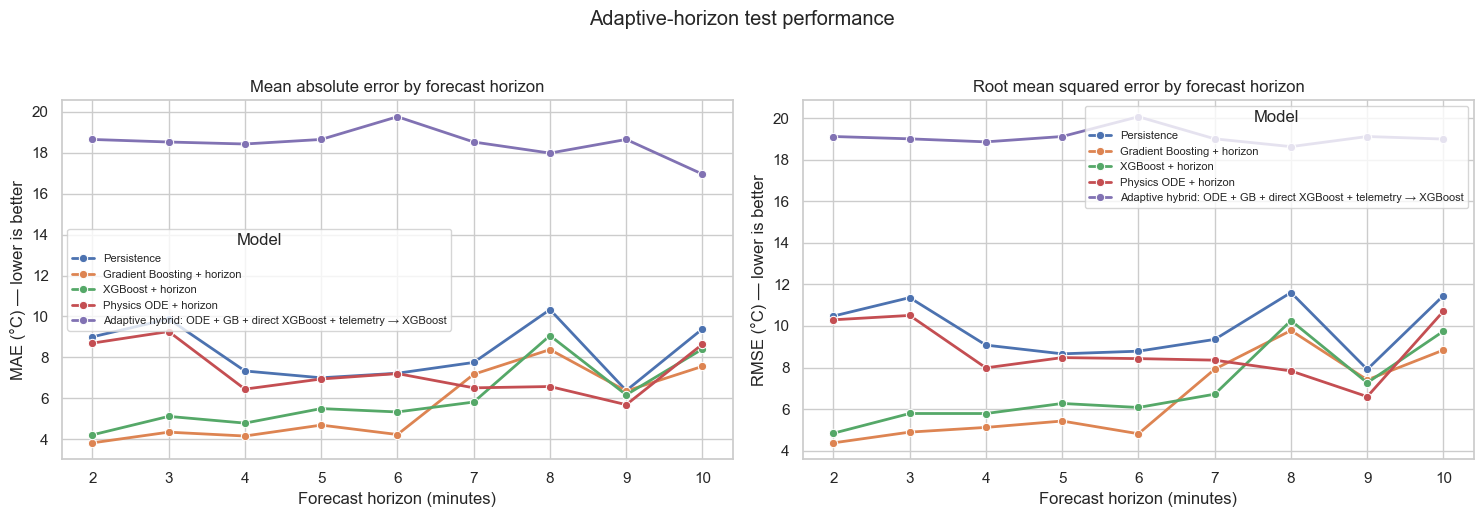

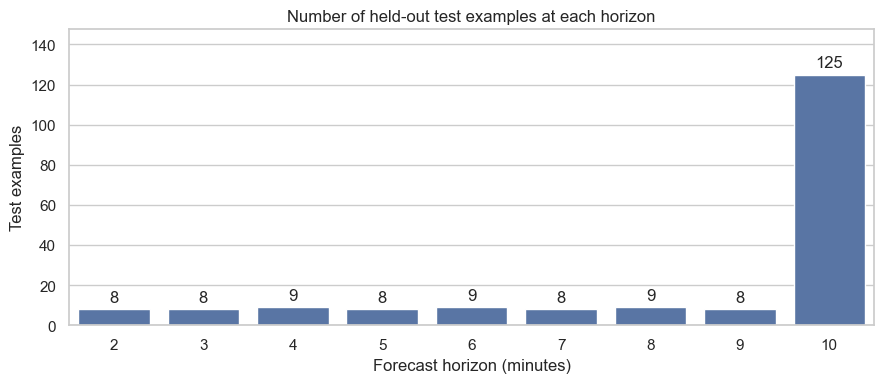

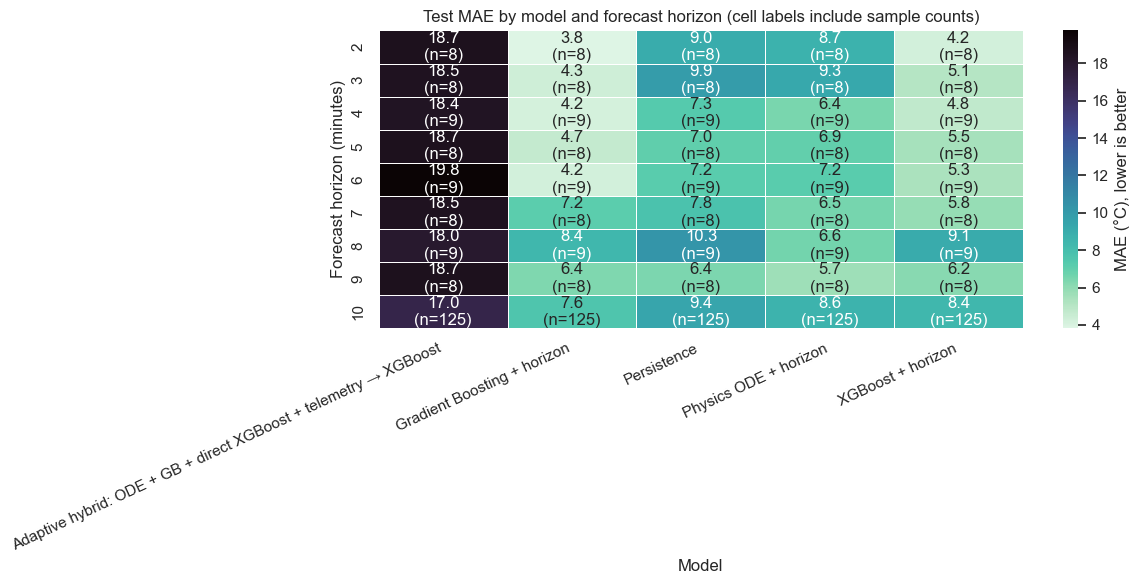

In [9]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
test_plot_data = adaptive_score_table[adaptive_score_table["partition"] == "test"].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, metric, title in [
    (axes[0], "MAE (°C)", "Mean absolute error by forecast horizon"),
    (axes[1], "RMSE (°C)", "Root mean squared error by forecast horizon"),
]:
    sns.lineplot(data=test_plot_data, x="horizon_minutes", y=metric, hue="model",
                 marker="o", linewidth=2, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Forecast horizon (minutes)")
    ax.set_ylabel(f"{metric} — lower is better")
    ax.set_xticks(sorted(test_plot_data["horizon_minutes"].unique()))
    ax.legend(title="Model", fontsize=8)
fig.suptitle("Adaptive-horizon test performance", y=1.03)
fig.tight_layout()
plt.show()

counts = (test_plot_data[["horizon_minutes", "examples"]]
          .drop_duplicates()
          .sort_values("horizon_minutes"))
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=counts, x="horizon_minutes", y="examples", color=sns.color_palette()[0], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
ax.set_title("Number of held-out test examples at each horizon")
ax.set_xlabel("Forecast horizon (minutes)")
ax.set_ylabel("Test examples")
ax.set_ylim(0, max(counts["examples"]) * 1.18)
fig.tight_layout()
plt.show()

mae_table = test_plot_data.pivot(index="horizon_minutes", columns="model", values="MAE (°C)")
count_table = test_plot_data.pivot(index="horizon_minutes", columns="model", values="examples")
annotations = mae_table.copy().astype(object)
for horizon in mae_table.index:
    for model in mae_table.columns:
        value = mae_table.loc[horizon, model]
        count = count_table.loc[horizon, model]
        annotations.loc[horizon, model] = "" if pd.isna(value) else f"{value:.1f}\n(n={int(count)})"
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(mae_table, annot=annotations, fmt="", cmap="mako_r", linewidths=0.5,
            cbar_kws={"label": "MAE (°C), lower is better"}, ax=ax)
ax.set_title("Test MAE by model and forecast horizon (cell labels include sample counts)")
ax.set_xlabel("Model")
ax.set_ylabel("Forecast horizon (minutes)")
plt.xticks(rotation=25, ha="right")
fig.tight_layout()
plt.show()


## Fair adaptive vs fixed five-minute comparison with estimator tuning

Both Gradient Boosting variants use the same chronological partitions and the same held-out five-minute examples. The adaptive model trains on 2–10 minute labels from training-period timestamps only, with horizon as an input. A ten-minute embargo protects the split because adaptive training labels can extend ten minutes ahead. We choose `n_estimators` using validation MAE from a 150/300/500/750 sweep, then refit on train plus validation and score the untouched test set.

In [ ]:
import smarttherm_ml.dataset as fair_dataset
import smarttherm_ml.training as fair_training

# Fixed five-minute examples define the common chronological split.
fair_dataset.TARGET_HORIZON_SECONDS = 300
fair_by_component, _ = fair_dataset.build_examples(points)
fair_five = fair_by_component["CPU"]
# Use a ten-minute embargo for all partitions because adaptive labels reach 10 min.
fair_training.TARGET_HORIZON_SECONDS = 600
fair_train, fair_validation, fair_test = fair_training.split_chronologically(fair_five)
fair_key = lambda item: (item.session_id, item.timestamp)
fair_train_keys = {fair_key(item) for item in fair_train}
fair_validation_keys = {fair_key(item) for item in fair_validation}

def fair_features(rows):
    return fair_training._features_matrix(rows)

def fair_horizon_features(items):
    return np.column_stack([
        fair_features([item for _, item in items]),
        np.asarray([minutes for minutes, _ in items], dtype=float),
    ])

# Collect 2–10 minute labels only for anchors in the train or validation partition.
fair_adaptive_train, fair_adaptive_validation = [], []
for minutes in range(2, 11):
    fair_dataset.TARGET_HORIZON_SECONDS = minutes * 60
    horizon_examples, _ = fair_dataset.build_examples(points)
    for item in horizon_examples["CPU"]:
        anchor = fair_key(item)
        if anchor in fair_train_keys:
            fair_adaptive_train.append((minutes, item))
        elif anchor in fair_validation_keys:
            fair_adaptive_validation.append((minutes, item))
fair_dataset.TARGET_HORIZON_SECONDS = 600
fair_training.TARGET_HORIZON_SECONDS = 600

fair_x_train = fair_features(fair_train)
fair_x_validation = fair_features(fair_validation)
fair_x_test = fair_features(fair_test)
fair_y_train = np.asarray([item.target_c for item in fair_train], dtype=float)
fair_y_validation = np.asarray([item.target_c for item in fair_validation], dtype=float)
fair_y_test = np.asarray([item.target_c for item in fair_test], dtype=float)
fair_adapt_x_train = fair_horizon_features(fair_adaptive_train)
fair_adapt_y_train = np.asarray([item.target_c for _, item in fair_adaptive_train], dtype=float)
fair_adapt_x_validation = fair_horizon_features(fair_adaptive_validation)
fair_adapt_y_validation = np.asarray([item.target_c for _, item in fair_adaptive_validation], dtype=float)
fair_adapt_x_validation_5m = np.column_stack([fair_x_validation, np.full(len(fair_validation), 5.0)])
fair_adapt_x_test_5m = np.column_stack([fair_x_test, np.full(len(fair_test), 5.0)])

def fair_make_gb(n_estimators):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("regressor", GradientBoostingRegressor(
            loss="huber", n_estimators=n_estimators, learning_rate=0.04,
            max_depth=3, min_samples_leaf=5, random_state=42)),
    ])

fair_grid = [150, 300, 500, 750]
fair_validation_rows = []
for name, x_train, y_train, x_validation in [
    ("Fixed Gradient Boosting", fair_x_train, fair_y_train, fair_x_validation),
    ("Adaptive Gradient Boosting", fair_adapt_x_train, fair_adapt_y_train, fair_adapt_x_validation_5m),
]:
    for count in fair_grid:
        candidate = fair_make_gb(count).fit(x_train, y_train)
        prediction = candidate.predict(x_validation)
        error = prediction - fair_y_validation
        fair_validation_rows.append({
            "model": name, "n_estimators": count,
            "validation_MAE (°C)": float(np.mean(np.abs(error))),
            "validation_RMSE (°C)": float(np.sqrt(np.mean(error ** 2))),
        })
fair_validation_table = pd.DataFrame(fair_validation_rows)
print(f"Five-minute train/validation/test anchors: {len(fair_train)}/{len(fair_validation)}/{len(fair_test)}")
print(f"Adaptive multi-horizon train/validation rows: {len(fair_adaptive_train)}/{len(fair_adaptive_validation)}")
print("Validation estimator sweep (selection uses validation MAE):")
print(fair_validation_table.round(4).to_string(index=False))
fair_selected = fair_validation_table.loc[
    fair_validation_table.groupby("model")["validation_MAE (°C)"].idxmin()
].set_index("model")["n_estimators"].to_dict()

# Refit the selected counts on train + validation; test remains untouched.
fair_train_validation = fair_train + fair_validation
fair_adaptive_train_validation = fair_adaptive_train + fair_adaptive_validation
fair_final_rows = []
for name, count, x_train, y_train, x_test in [
    ("Fixed Gradient Boosting", int(fair_selected["Fixed Gradient Boosting"]),
     fair_features(fair_train_validation),
     np.asarray([item.target_c for item in fair_train_validation], dtype=float), fair_x_test),
    ("Adaptive Gradient Boosting", int(fair_selected["Adaptive Gradient Boosting"]),
     fair_horizon_features(fair_adaptive_train_validation),
     np.asarray([item.target_c for _, item in fair_adaptive_train_validation], dtype=float), fair_adapt_x_test_5m),
]:
    final_model = fair_make_gb(count).fit(x_train, y_train)
    prediction = final_model.predict(x_test)
    error = prediction - fair_y_test
    fair_final_rows.append({
        "model": name, "selected_estimators": count, "final_training_rows": len(y_train),
        "shared_test_examples": len(fair_test),
        "test_MAE (°C)": float(np.mean(np.abs(error))),
        "test_RMSE (°C)": float(np.sqrt(np.mean(error ** 2))),
        "test_R²": float(1 - np.sum(error ** 2) / np.sum((fair_y_test - np.mean(fair_y_test)) ** 2)),
        "mean_signed_error (°C)": float(np.mean(error)),
    })
print("Final comparison on the shared, untouched five-minute test set:")
print(pd.DataFrame(fair_final_rows).round(4).to_string(index=False))

Five-minute train/validation/test anchors: 1719/626/1128
Adaptive multi-horizon train/validation rows: 12420/4938
Validation estimator sweep (selection uses validation MAE):
                     model  n_estimators  validation_MAE (°C)  validation_RMSE (°C)
   Fixed Gradient Boosting           150              13.0237               15.8099
   Fixed Gradient Boosting           300              14.2576               17.3420
   Fixed Gradient Boosting           500              15.0888               18.3535
   Fixed Gradient Boosting           750              15.3306               18.6312
Adaptive Gradient Boosting           150              10.6974               12.8020
Adaptive Gradient Boosting           300              12.1656               14.9045
Adaptive Gradient Boosting           500              13.1802               16.3679
Adaptive Gradient Boosting           750              13.6868               17.1755
Final comparison on the shared, untouched five-minute test set:
      

## Scaling and causal temperature-feature comparison (2–6 minutes)

This follow-up compares the existing unscaled features with `StandardScaler`, `MinMaxScaler`, the temperature change from the preceding CPU reading, and both that change plus current temperature divided by the maximum CPU temperature observed in the **preceding 120 seconds**. The engineered features use past readings only. Scalers are fit inside each training pipeline, so validation and test data do not affect their fitted ranges. The fixed Gradient Boosting and XGBoost models are evaluated alongside adaptive Gradient Boosting on the same 1,396 train, 370 validation, and 551 test anchor timestamps for each 2–6 minute horizon.

Run the next cell to regenerate the comparison CSV and show the best horizon for each model and feature variant. These are research comparisons; they do not change the integrated production model.

In [ ]:
import subprocess
scaling_script = ML_DIR / "experiments" / "compare_feature_scaling.py"
scaling_run = subprocess.run([sys.executable, str(scaling_script)], cwd=ROOT, check=True, capture_output=True, text=True)
print(scaling_run.stdout)
scaling_metrics = pd.read_csv(ML_DIR / "experiments" / "reports" / "scaling_and_temperature_feature_metrics_2_to_6.csv")
scaling_best = scaling_metrics.loc[scaling_metrics.groupby(["model", "variant"])["MAE_C"].idxmin()]
display(scaling_best.sort_values(["model", "MAE_C"])[["model", "variant", "horizon_min", "MAE_C", "RMSE_C", "R2"]].round(3).reset_index(drop=True))